# MLB Game Simulator: Visualizations Workbook

This code creates the visualizations used in the final report of our project.

In [19]:
# import all libraries and install seaborn if you haven't already
# pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Placeholder Data Creation

Here we have the code that creates placeholder data for all the visualizations.

For the final project this section will be replaced with a data cleaning section.

In [20]:
# First create a simple dataframe for the heatmap
mock_data = {
    "Opposing Team 1": [50, 35, 60],
    "Opposing Team 2": [40, 70, 35],
    "Opposing Team 3": [10, 40, 50]
}
mock_configurations = ["Tigers Config 1", "Tigers Config 2", "Tigers Config 3"]
mock_df = pd.DataFrame(mock_data, index=mock_configurations)


In [21]:
# Next create poisson randomly distributed runs for 1000 simulated baseball games.
# This data will be used for the bar chart visual.
np.random.seed(42)
simulated_runs = np.random.poisson(lam=5, size=1000)

# Quick calculation to get the percentage of games for each run total
run_percentages = (
    pd.Series(simulated_runs)
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

# Convert percentages into a DataFrame for plotting
bar_data = pd.DataFrame({
    "Runs": run_percentages.index,
    "Percentage of Games": run_percentages.values
})

# Finally note the actual runs scored for the visual
actual_runs = 7


In [22]:
# Finally, generate sample results for 1,000 simulated games
# If '1' -> Team A wins or if '0' -> Team A loses
# We can also tweak the win rate here
np.random.seed(42)
simulated_game_results = np.random.choice(
    [0, 1],
    size=1000,
    p=[0.45, 0.55]
)

# Calculate the win percentage for each simulation game to be plotted
simulation_numbers = np.arange(1, 1001)
cumulative_wins = np.cumsum(simulated_game_results)
win_percentages = (
    cumulative_wins / simulation_numbers
) * 100

# Convert the win percentages into a DataFrame for plotting
df = pd.DataFrame({
    "Simulation Number": simulation_numbers,
    "Rolling Win Percentage": win_percentages
})

# Visualization Creation

This section is where the visuals are actually created with the cleaned data.

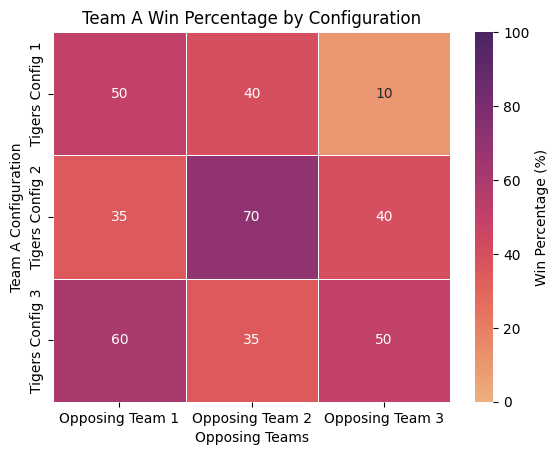

In [23]:
# Now create the heatmap using seaborn
def format_percentage(value):
    return f'{value:.1f}%'

sns.heatmap(
    mock_df,
    annot=True,
    cmap = sns.color_palette("flare", as_cmap=True),
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Win Percentage (%)"}
)

# Next add the titles and labels
plt.title("Team A Win Percentage by Configuration")
plt.xlabel("Opposing Teams")
plt.ylabel("Team A Configuration")

# Finally, display the heatmap
plt.show()

/tmp/ipykernel_11136/3209009320.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


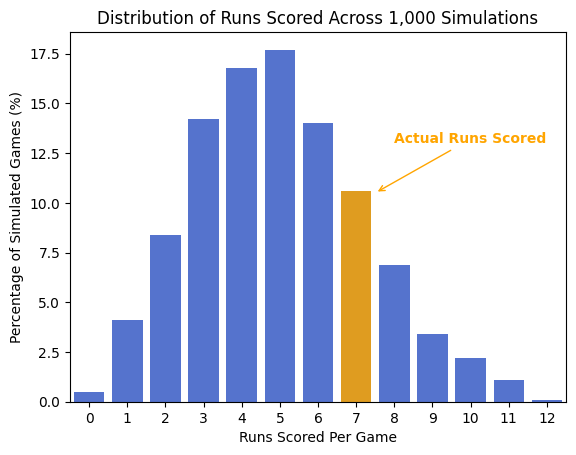

In [24]:
# This cusotm color theme makes the actual runs bar a different color than the rest
bar_colors = [
    "orange" if runs == actual_runs else "royalblue"
    for runs in bar_data["Runs"]
]

# Create the bar chart using seaborn
sns.barplot(
    data=bar_data,
    x="Runs",
    y="Percentage of Games",
    palette=bar_colors
)

# Next add the titles and labels
plt.title("Distribution of Runs Scored Across 1,000 Simulations")
plt.xlabel("Runs Scored Per Game")
plt.ylabel("Percentage of Simulated Games (%)")

# Here I also add an annotation and arrow to highlight the actual runs scored
plt.annotate(
    f"Actual Runs Scored",
    xy=(7.5, 10.5),
    xytext=(8, 13),
    arrowprops=dict(arrowstyle="->", color="orange"),
    color="orange",
    fontsize=10,
    fontweight="bold"
)


# Finally, display the heatmap
plt.show()

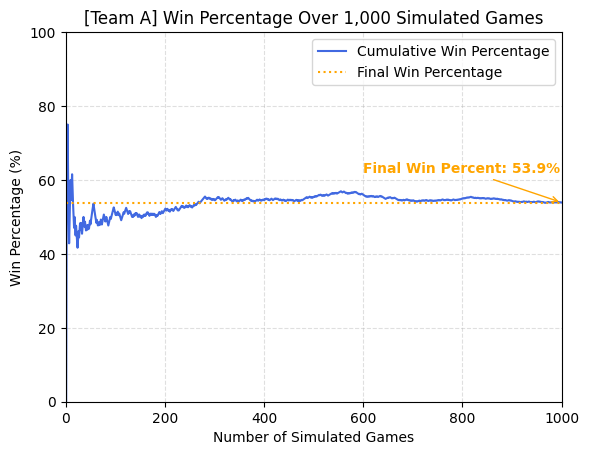

In [25]:
# Create line chart using seaborn
sns.lineplot(
    data=df,
    x="Simulation Number",
    y="Rolling Win Percentage",
    color="royalblue",
    label="Cumulative Win Percentage"
)

# Next, add final win percentage reference line
plt.axhline(
    y=win_percentages[-1],
    color="orange",
    linestyle="dotted",
    label="Final Win Percentage"
)

# Here I also add an annotation and arrow to highlight the final win percentage
plt.annotate(
    f"Final Win Percent: {win_percentages[-1]:.1f}%",
    xy=(1000, win_percentages[-1]),
    xytext=(600, win_percentages[-1] + 8),
    arrowprops=dict(arrowstyle="->", color="orange"),
    color="orange",
    fontsize=10,
    fontweight="bold"
)

# Next add the titles and labels
plt.title("[Team A] Win Percentage Over 1,000 Simulated Games")
plt.xlabel("Number of Simulated Games")
plt.ylabel("Win Percentage (%)")

# Finally shape our chart and display the chart
plt.ylim(0, 100)
plt.xlim(0, 1000)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.show()